# NB03 — Data Analysis

## Project question

**How did consumer-price inflation and youth unemployment differ across Italy, Türkiye, and the United Kingdom from 2010 to 2025?**

## Purpose

This notebook explores the analysis-ready country-year table created in NB02.

The analysis will:

1. verify the processed input;
2. examine inflation trends across the three countries;
3. examine youth-unemployment trends across the three countries;
4. investigate how the two indicators changed over time;
5. develop two or three central findings for the public project page.

The analysis is exploratory and descriptive. Patterns occurring at the same time will not be interpreted as evidence that inflation caused changes in youth unemployment.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
FIGURE_DIR = Path("../docs/assets")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR.resolve())

Figure directory: /files/assignments/final-project/docs/assets


## Loading and validating the processed data

NB03 reads the analysis-ready table created in NB02. Before beginning the
exploration, the notebook checks its expected columns, countries, annual
coverage, missing values, and country-year uniqueness.

In [3]:
DATA_FILE = Path(
    "../data/processed/country_year_indicators.csv"
)

df = pd.read_csv(DATA_FILE)

print("Data file:", DATA_FILE.resolve())
print("Shape:", df.shape)


Data file: /files/assignments/final-project/data/processed/country_year_indicators.csv
Shape: (48, 5)


In [4]:
required_columns = [
    "country_code",
    "country",
    "year",
    "inflation_pct",
    "youth_unemployment_pct",
]

expected_countries = {"GBR", "ITA", "TUR"}

if list(df.columns) != required_columns:
    raise ValueError(
        "The processed table has unexpected columns."
    )

missing_values = df[required_columns].isna().sum()

duplicate_country_years = df.duplicated(
    subset=["country_code", "year"]
).sum()

rows_per_country = (
    df["country_code"]
    .value_counts()
    .sort_index()
)

print("Columns:", list(df.columns))

print("\nColumn types:")
print(df.dtypes)

print("\nCountries:")
print(sorted(df["country_code"].unique()))

print("\nMissing values:")
print(missing_values)

print(
    "\nDuplicate country-year rows:",
    duplicate_country_years,
)

print("\nRows per country:")
print(rows_per_country)

print(
    "\nYear range:",
    f"{df['year'].min()}–{df['year'].max()}",
)

if df.shape != (48, 5):
    raise ValueError(
        "The processed table has an unexpected shape."
    )

if set(df["country_code"]) != expected_countries:
    raise ValueError(
        "The processed table contains unexpected countries."
    )

if not (rows_per_country == 16).all():
    raise ValueError(
        "Each country should have 16 annual observations."
    )

if (df["year"].min(), df["year"].max()) != (2010, 2025):
    raise ValueError(
        "The processed table should cover 2010–2025."
    )

if missing_values.sum() != 0:
    raise ValueError(
        "The processed table contains missing values."
    )

if duplicate_country_years != 0:
    raise ValueError(
        "The processed table contains duplicate country-year rows."
    )

Columns: ['country_code', 'country', 'year', 'inflation_pct', 'youth_unemployment_pct']

Column types:
country_code               object
country                    object
year                        int64
inflation_pct             float64
youth_unemployment_pct    float64
dtype: object

Countries:
['GBR', 'ITA', 'TUR']

Missing values:
country_code              0
country                   0
year                      0
inflation_pct             0
youth_unemployment_pct    0
dtype: int64

Duplicate country-year rows: 0

Rows per country:
country_code
GBR    16
ITA    16
TUR    16
Name: count, dtype: int64

Year range: 2010–2025


In [5]:
df = (
    df
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)

df.groupby("country_code").head(2)

,country_code,country,year,inflation_pct,youth_unemployment_pct
0,GBR,United Kingdom,2010,2.492655,20.328
1,GBR,United Kingdom,2011,3.856112,21.689
16,ITA,Italy,2010,1.525516,27.910
17,ITA,Italy,2011,2.780633,29.145
32,TUR,Turkiye,2010,8.566444,21.578
33,TUR,Turkiye,2011,6.471880,18.208


## Analysis-specific tables

The processed file already contains the complete country-year structure. The following method chains select and organize only the variables needed for each part of the analysis. They do not repeat the raw-data extraction or reshaping performed in NB02.

In [6]:
inflation_df = (
    df
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "inflation_pct",
        ],
    ]
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)

inflation_df.groupby("country_code").head(1)

,country_code,country,year,inflation_pct
0,GBR,United Kingdom,2010,2.492655
16,ITA,Italy,2010,1.525516
32,TUR,Turkiye,2010,8.566444


In [7]:
unemployment_df = (
    df
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "youth_unemployment_pct",
        ],
    ]
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)

unemployment_df.groupby("country_code").head(1)

,country_code,country,year,youth_unemployment_pct
0,GBR,United Kingdom,2010,20.328
16,ITA,Italy,2010,27.910
32,TUR,Turkiye,2010,21.578


In [8]:
country_ranges = (
    df
    .groupby(
        ["country_code", "country"],
        as_index=False,
    )
    .agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        observations=("year", "size"),
        minimum_inflation=(
            "inflation_pct",
            "min",
        ),
        maximum_inflation=(
            "inflation_pct",
            "max",
        ),
        minimum_youth_unemployment=(
            "youth_unemployment_pct",
            "min",
        ),
        maximum_youth_unemployment=(
            "youth_unemployment_pct",
            "max",
        ),
    )
)

country_ranges

,country_code,country,first_year,last_year,observations,minimum_inflation,maximum_inflation,minimum_youth_unemployment,maximum_youth_unemployment
0,GBR,United Kingdom,2010,2025,16,0.368047,7.922049,10.589,22.106
1,ITA,Italy,2010,2025,16,-0.137708,8.201290,20.246,42.669
2,TUR,Turkiye,2010,2025,16,6.471880,72.308836,16.042,25.039


### Locating observed minima and maxima

For each country, `idxmin()` and `idxmax()` identify the row containing
the lowest and highest observed value. Selecting those rows retains both
the value and its year. `pd.concat()` then combines the minimum and
maximum rows into one summary table.

In [9]:
inflation_extremes = pd.concat(
    [
        inflation_df.loc[
            inflation_df
            .groupby("country_code")["inflation_pct"]
            .idxmin()
        ].assign(extreme="Minimum"),
        inflation_df.loc[
            inflation_df
            .groupby("country_code")["inflation_pct"]
            .idxmax()
        ].assign(extreme="Maximum"),
    ],
    ignore_index=True,
).sort_values(
    ["country_code", "extreme"]
)

inflation_extremes

,country_code,country,year,inflation_pct,extreme
3,GBR,United Kingdom,2022,7.922049,Maximum
0,GBR,United Kingdom,2015,0.368047,Minimum
4,ITA,Italy,2022,8.201290,Maximum
1,ITA,Italy,2020,-0.137708,Minimum
5,TUR,Turkiye,2022,72.308836,Maximum
2,TUR,Turkiye,2011,6.471880,Minimum


In [10]:
unemployment_extremes = pd.concat(
    [
        unemployment_df.loc[
            unemployment_df
            .groupby("country_code")[
                "youth_unemployment_pct"
            ]
            .idxmin()
        ].assign(extreme="Minimum"),
        unemployment_df.loc[
            unemployment_df
            .groupby("country_code")[
                "youth_unemployment_pct"
            ]
            .idxmax()
        ].assign(extreme="Maximum"),
    ],
    ignore_index=True,
).sort_values(
    ["country_code", "extreme"]
)

unemployment_extremes

,country_code,country,year,youth_unemployment_pct,extreme
3,GBR,United Kingdom,2012,22.106,Maximum
0,GBR,United Kingdom,2022,10.589,Minimum
4,ITA,Italy,2014,42.669,Maximum
1,ITA,Italy,2024,20.246,Minimum
5,TUR,Turkiye,2019,25.039,Maximum
2,TUR,Turkiye,2025,16.042,Minimum


## Inflation trends

The country-level ranges show that all three countries reached their maximum inflation rate in 2022. The following line chart examines how they arrived at that point and how their inflation paths differed across the full period.

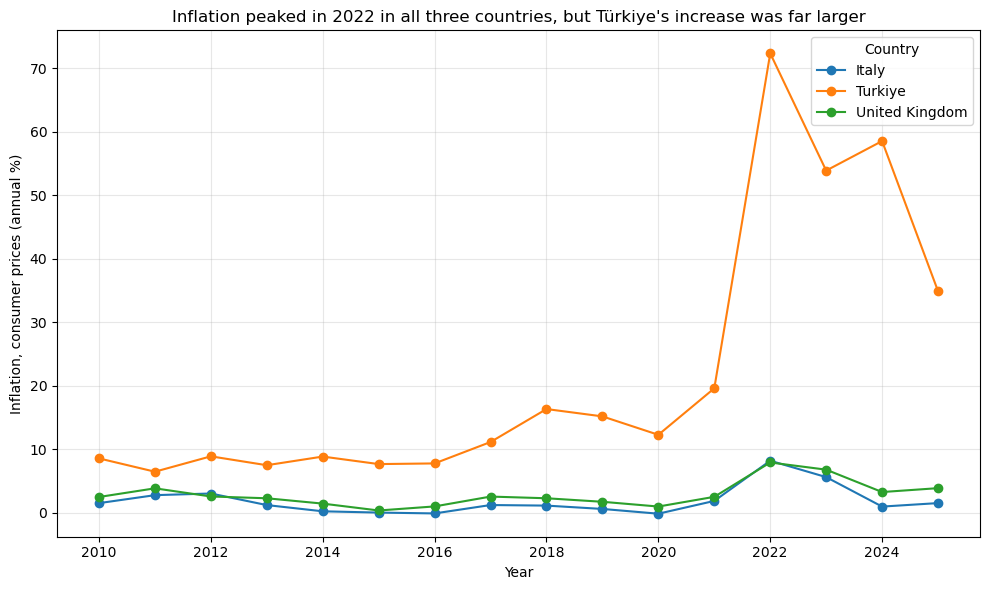

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

for country, country_df in inflation_df.groupby("country"):
    ax.plot(
        country_df["year"],
        country_df["inflation_pct"],
        marker="o",
        label=country,
    )

ax.set_title(
    "Inflation peaked in 2022 in all three countries, "
    "but Türkiye's increase was far larger"
)
ax.set_xlabel("Year")
ax.set_ylabel("Inflation, consumer prices (annual %)")
ax.set_xticks(range(2010, 2026, 2))
ax.legend(title="Country")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "inflation_all_countries.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

The full comparison is necessary to show the scale of Türkiye's inflation. However, that scale makes the smaller movements in Italy and the United Kingdom difficult to inspect. A second view therefore focuses only on those two countries without changing or excluding them from the full comparison above.

In [12]:
italy_uk_inflation_df = (
    inflation_df
    .query("country_code in ['GBR', 'ITA']")
    .sort_values(["country_code", "year"])
    .reset_index(drop=True)
)

italy_uk_inflation_df.groupby("country_code").head(2)

,country_code,country,year,inflation_pct
0,GBR,United Kingdom,2010,2.492655
1,GBR,United Kingdom,2011,3.856112
16,ITA,Italy,2010,1.525516
17,ITA,Italy,2011,2.780633


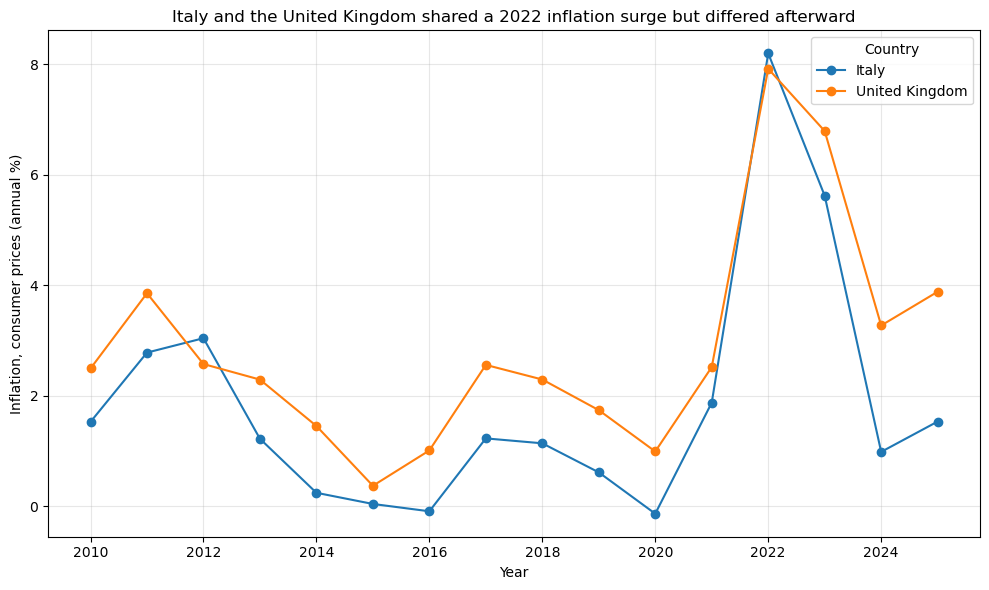

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))

for country, country_df in italy_uk_inflation_df.groupby("country"):
    ax.plot(
        country_df["year"],
        country_df["inflation_pct"],
        marker="o",
        label=country,
    )

ax.set_title(
    "Italy and the United Kingdom shared a 2022 inflation surge "
    "but differed afterward"
)
ax.set_xlabel("Year")
ax.set_ylabel("Inflation, consumer prices (annual %)")
ax.set_xticks(range(2010, 2026, 2))
ax.legend(title="Country")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "inflation_italy_uk.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Youth-unemployment trends

Unlike inflation, youth unemployment reached its maximum in a different year for each country. The next chart examines whether the countries followed similar trajectories despite the different peak years.

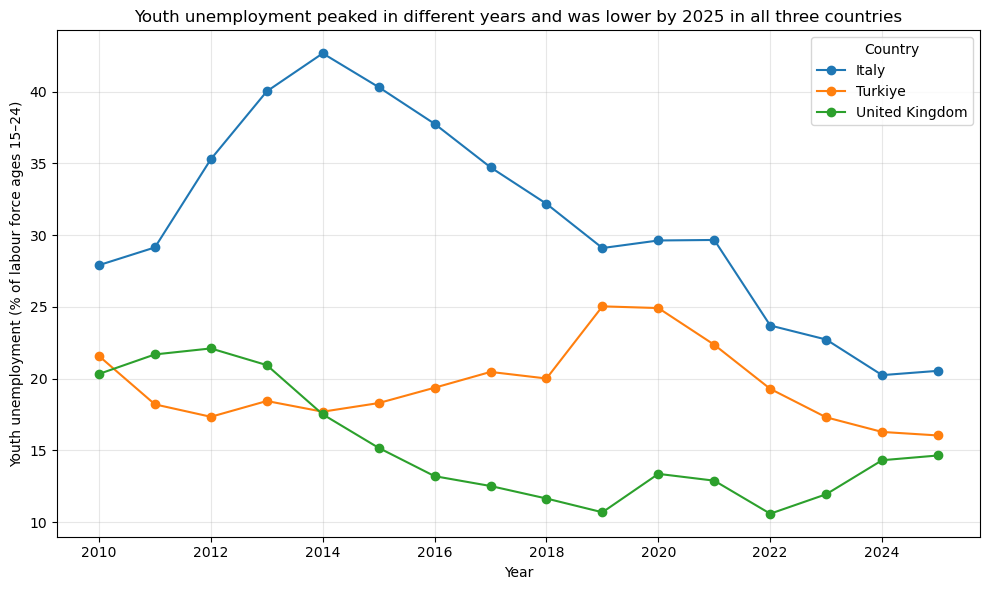

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

for country, country_df in unemployment_df.groupby("country"):
    ax.plot(
        country_df["year"],
        country_df["youth_unemployment_pct"],
        marker="o",
        label=country,
    )

ax.set_title(
    "Youth unemployment peaked in different years "
    "and was lower by 2025 in all three countries"
)
ax.set_xlabel("Year")
ax.set_ylabel(
    "Youth unemployment "
    "(% of labour force ages 15–24)"
)
ax.set_xticks(range(2010, 2026, 2))
ax.legend(title="Country")
ax.grid(True, alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURE_DIR / "youth_unemployment.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()

## Comparing the timing of the peaks

A shared high or low value does not establish a relationship between the two indicators. As a first timing comparison, the table below identifies how many years separated each country's maximum inflation rate from its maximum youth-unemployment rate.

In all three countries, the youth-unemployment maximum occurred before
the inflation maximum. The year difference therefore shows how many
calendar years separated the earlier youth-unemployment peak from the
later inflation peak. It is a descriptive timing comparison and does not
establish a relationship between the indicators.

### Combining country-level results

`merge()` joins the inflation and youth-unemployment summaries using the
country identifiers. `assign()` then creates a new column from existing
columns. The lambda expression receives the merged table and calculates
the year difference for each country.

The same merge-and-assign pattern is used later to calculate changes
between selected years and observed extrema.

In [15]:
inflation_peak_df = (
    inflation_extremes
    .query("extreme == 'Maximum'")
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "inflation_pct",
        ],
    ]
    .rename(
        columns={
            "year": "inflation_peak_year",
            "inflation_pct": "maximum_inflation_pct",
        }
    )
)

unemployment_peak_df = (
    unemployment_extremes
    .query("extreme == 'Maximum'")
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "year": "youth_unemployment_peak_year",
            "youth_unemployment_pct": (
                "maximum_youth_unemployment_pct"
            ),
        }
    )
)

peak_timing_df = (
    inflation_peak_df
    .merge(
        unemployment_peak_df,
        on=["country_code", "country"],
    )
    .assign(
        years_between_peaks=lambda table: (
            table["inflation_peak_year"]
            - table["youth_unemployment_peak_year"]
        )
    )
)

peak_timing_df

,country_code,country,inflation_peak_year,maximum_inflation_pct,youth_unemployment_peak_year,maximum_youth_unemployment_pct,years_between_peaks
0,GBR,United Kingdom,2022,7.922049,2012,22.106,10
1,ITA,Italy,2022,8.201290,2014,42.669,8
2,TUR,Turkiye,2022,72.308836,2019,25.039,3


## Changes from observed peaks to 2025

The charts show the broad trajectories, while the following comparisons
quantify the changes in percentage points.

For inflation, each country's 2022 value is matched with its 2025 value
because all three countries reached their observed maximum in 2022.

For youth unemployment, each country's maximum and minimum are compared
with its 2025 value. Including the minimum shows whether the 2025 rate
remained at the lowest observed level or had increased again after reaching
it.

In [16]:
inflation_2022_df = (
    inflation_df
    .query("year == 2022")
    .loc[
        :,
        [
            "country_code",
            "country",
            "inflation_pct",
        ],
    ]
    .rename(
        columns={
            "inflation_pct": "inflation_2022_pct",
        }
    )
)

inflation_2025_df = (
    inflation_df
    .query("year == 2025")
    .loc[
        :,
        [
            "country_code",
            "country",
            "inflation_pct",
        ],
    ]
    .rename(
        columns={
            "inflation_pct": "inflation_2025_pct",
        }
    )
)

inflation_change_df = (
    inflation_2022_df
    .merge(
        inflation_2025_df,
        on=["country_code", "country"],
    )
    .assign(
        decline_2022_to_2025_pct_points=lambda table: (
            table["inflation_2022_pct"]
            - table["inflation_2025_pct"]
        )
    )
    .sort_values(
        "inflation_2022_pct",
        ascending=False,
    )
    .reset_index(drop=True)
    .round(3)
)

inflation_change_df

,country_code,country,inflation_2022_pct,inflation_2025_pct,decline_2022_to_2025_pct_points
0,TUR,Turkiye,72.309,34.881,37.428
1,ITA,Italy,8.201,1.532,6.670
2,GBR,United Kingdom,7.922,3.883,4.039


### Inflation after the shared 2022 peak

Inflation declined in all three countries between 2022 and 2025, but the scale remained very different.

Türkiye recorded the largest decline, falling by 37.428 percentage points from 72.309% to 34.881%. Despite that fall, its 2025 inflation rate remained far above those of the other two countries.

Italy's inflation declined by 6.670 percentage points, from 8.201% to 1.532%, while the United Kingdom's declined by 4.039 points, from 7.922% to 3.883%.

In [17]:
youth_peak_df = (
    unemployment_extremes
    .query("extreme == 'Maximum'")
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "year": "peak_year",
            "youth_unemployment_pct": (
                "peak_youth_unemployment_pct"
            ),
        }
    )
)

youth_minimum_df = (
    unemployment_extremes
    .query("extreme == 'Minimum'")
    .loc[
        :,
        [
            "country_code",
            "country",
            "year",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "year": "minimum_year",
            "youth_unemployment_pct": (
                "minimum_youth_unemployment_pct"
            ),
        }
    )
)

youth_2025_df = (
    unemployment_df
    .query("year == 2025")
    .loc[
        :,
        [
            "country_code",
            "country",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "youth_unemployment_pct": (
                "youth_unemployment_2025_pct"
            ),
        }
    )
)

youth_change_df = (
    youth_peak_df
    .merge(
        youth_minimum_df,
        on=["country_code", "country"],
    )
    .merge(
        youth_2025_df,
        on=["country_code", "country"],
    )
    .assign(
        decline_peak_to_2025_pct_points=lambda table: (
            table["peak_youth_unemployment_pct"]
            - table["youth_unemployment_2025_pct"]
        ),
        increase_minimum_to_2025_pct_points=lambda table: (
            table["youth_unemployment_2025_pct"]
            - table["minimum_youth_unemployment_pct"]
        ),
    )
    .sort_values("country_code")
    .reset_index(drop=True)
    .round(3)
)

youth_change_df

,country_code,country,peak_year,peak_youth_unemployment_pct,minimum_year,minimum_youth_unemployment_pct,youth_unemployment_2025_pct,decline_peak_to_2025_pct_points,increase_minimum_to_2025_pct_points
0,GBR,United Kingdom,2012,22.106,2022,10.589,14.647,7.459,4.058
1,ITA,Italy,2014,42.669,2024,20.246,20.545,22.124,0.299
2,TUR,Turkiye,2019,25.039,2025,16.042,16.042,8.997,0.000


### Youth unemployment after each country's peak

The youth-unemployment trajectories were not synchronised across the three countries.

Italy experienced the largest peak-to-2025 decline, falling by 22.124 percentage points from its 2014 maximum of 42.669% to 20.545% in 2025. Its 2025 value was only 0.299 points above its observed minimum in 2024.

The United Kingdom fell by 7.459 percentage points from its 2012 maximum to 14.647% in 2025. However, youth unemployment had reached a lower value of 10.589% in 2022 and subsequently increased by 4.058 points.

Türkiye declined by 8.997 percentage points from its 2019 maximum of 25.039% and reached its observed minimum of 16.042% in 2025.

## Change across the full study period

The peak-based comparisons show turning points within the period. The following table directly compares 2010 with 2025 to show how each indicator changed between the first and final observed years.

In [18]:
start_year_df = (
    df
    .query("year == 2010")
    .loc[
        :,
        [
            "country_code",
            "country",
            "inflation_pct",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "inflation_pct": "inflation_2010_pct",
            "youth_unemployment_pct": (
                "youth_unemployment_2010_pct"
            ),
        }
    )
)

end_year_df = (
    df
    .query("year == 2025")
    .loc[
        :,
        [
            "country_code",
            "country",
            "inflation_pct",
            "youth_unemployment_pct",
        ],
    ]
    .rename(
        columns={
            "inflation_pct": "inflation_2025_pct",
            "youth_unemployment_pct": (
                "youth_unemployment_2025_pct"
            ),
        }
    )
)

period_change_df = (
    start_year_df
    .merge(
        end_year_df,
        on=["country_code", "country"],
    )
    .assign(
        inflation_change_pct_points=lambda table: (
            table["inflation_2025_pct"]
            - table["inflation_2010_pct"]
        ),
        youth_unemployment_change_pct_points=lambda table: (
            table["youth_unemployment_2025_pct"]
            - table["youth_unemployment_2010_pct"]
        ),
    )
    .sort_values("country_code")
    .reset_index(drop=True)
    .round(3)
)

period_change_df

,country_code,country,inflation_2010_pct,youth_unemployment_2010_pct,inflation_2025_pct,youth_unemployment_2025_pct,inflation_change_pct_points,youth_unemployment_change_pct_points
0,GBR,United Kingdom,2.493,20.328,3.883,14.647,1.390,-5.681
1,ITA,Italy,1.526,27.910,1.532,20.545,0.006,-7.365
2,TUR,Turkiye,8.566,21.578,34.881,16.042,26.315,-5.536


### Comparison between 2010 and 2025

Youth unemployment was lower in 2025 than in 2010 in all three countries. Italy recorded the largest decline, falling by 7.365 percentage points. The United Kingdom declined by 5.681 points, while Türkiye declined by 5.536 points.

The inflation comparison was substantially different. Türkiye's inflation rate was 26.315 percentage points higher in 2025 than in 2010. The United Kingdom ended 1.390 points higher. Italy's 2025 rate was only 0.006 points above its 2010 rate.

The similar Italian endpoint values do not mean that inflation remained stable throughout the period. Italy reached 8.201% in 2022 before falling to 1.532% in 2025. The full trend and peak comparisons are therefore necessary alongside the endpoint table.

## Central findings

### 1. Inflation peaked in the same year, but not on the same scale

All three countries recorded their maximum inflation rate in 2022. Italy reached 8.201% and the United Kingdom reached 7.922%, while Türkiye reached 72.309%. Türkiye's inflation remained much higher in 2025 despite declining by 37.428 percentage points from its peak.

### 2. Youth-unemployment trajectories were country-specific

Youth unemployment reached its maximum in different years: 2012 in the United Kingdom, 2014 in Italy, and 2019 in Türkiye. By 2025, the rate was lower than in 2010 in all three countries. Italy recorded the largest full-period decline, at 7.365 percentage points.

### 3. The two indicators did not share the same peak timing

Although inflation peaked in 2022 in every country, youth unemployment had reached its maximum earlier. The inflation peak occurred 10 years after the United Kingdom's youth-unemployment peak, 8 years after Italy's, and 3 years after Türkiye's.

This does not prove that the indicators are unrelated. It shows only that the data do not display a simple pattern in which inflation and youth unemployment reach their maximum in the same year.

## Limitations

This analysis is descriptive and is based on 16 annual observations for
each country from 2010 through 2025. It identifies differences, turning
points, and timing patterns but does not estimate causal effects.

Because the indicators are annual national measures, they cannot show
changes within individual years or differences between regions and groups
within each country. The peak-timing comparison therefore identifies only
the calendar year of each maximum and cannot establish more precise
within-year sequencing.

The youth-unemployment indicator is a modelled ILO estimate reported
through the World Bank Indicators API. Differences between countries may
also reflect structural, institutional, and labour-market conditions that
are not included in this dataset.

The findings therefore describe what occurred in these two indicators;
they do not establish that changes in one indicator caused changes in the
other.